# 3.1.4 — Elaboración real del Data-Set (PlantVillage + PlantDoc)
Proyecto: *Detección y Clasificación de Enfermedades en Plantas mediante Visión Artificial*
Curso: Inteligencia Artificial (Principios y Técnicas)


> Ambos datasets se descargan directamente desde sus repositorios oficiales en GitHub (públicos, sin necesidad de credenciales ni cuentas).


## 3.1.4.1 — Instalación de paquetes y configuración del entorno

In [ ]:
import os, shutil, re, glob
import pandas as pd
print('Entorno listo.')


Entorno listo.


In [ ]:
import os, shutil, re, glob
import pandas as pd
import numpy as np
from PIL import Image

## 3.1.4.2 — Descarga de PlantVillage (repositorio oficial en GitHub)

In [ ]:
# 3.1.4.2 — Verificación de PlantVillage

import os

PV_ROOT = "/content/plantvillage"

if os.path.exists(PV_ROOT):
    print("PlantVillage ya existe.")
    print("Se utilizará la carpeta existente.")
else:
    !git clone --depth 1 https://github.com/spMohanty/PlantVillage-Dataset.git /content/plantvillage
    print("PlantVillage descargado correctamente.")

assert os.path.exists(PV_ROOT), "No se encontró la carpeta de PlantVillage."

print("Ruta:", PV_ROOT)

Cloning into '/content/plantvillage'...
remote: Enumerating objects: 163219, done.
remote: Counting objects: 100% (163219/163219), done.
remote: Compressing objects: 100% (163125/163125), done.
remote: Total 163219 (delta 93), reused 163215 (delta 93), pack-reused 0 (from 0)
Receiving objects: 100% (163219/163219), 2.00 GiB | 17.25 MiB/s, done.
Resolving deltas: 100% (93/93), done.
Updating files: 100% (182404/182404), done.
PlantVillage descargado correctamente.
Ruta: /content/plantvillage




> El repositorio oficial de PlantVillage se clonó correctamente desde GitHub, obteniendo la carpeta `raw/color/` con las imágenes RGB originales organizadas por clase.


## 3.1.4.3 — Descarga de PlantDoc (repositorio oficial en GitHub)

In [ ]:
!git clone --depth 1 https://github.com/pratikkayal/PlantDoc-Dataset.git /content/plantdoc


Cloning into '/content/plantdoc'...
remote: Enumerating objects: 2628, done.
remote: Counting objects: 100% (2628/2628), done.
remote: Compressing objects: 100% (2627/2627), done.
remote: Total 2628 (delta 1), reused 2616 (delta 1), pack-reused 0 (from 0)
Receiving objects: 100% (2628/2628), 932.91 MiB | 17.33 MiB/s, done.
Resolving deltas: 100% (1/1), done.
Updating files: 100% (2581/2581), done.




> El repositorio oficial de PlantDoc se clonó correctamente, obteniendo las carpetas train/ y test/ con las imágenes originales.


## 3.1.4.4 — Verificación del volumen real de imágenes descargadas


In [ ]:
def count_images(root_dir, exts=('.jpg', '.jpeg', '.png', '.JPG', '.JPEG', '.PNG')):
    total = 0
    for dirpath, _, filenames in os.walk(root_dir):
        total += sum(1 for f in filenames if f.endswith(exts))
    return total

pv_root = '/content/plantvillage'
pd_root = '/content/plantdoc'

# Se cuenta solo la variante 'color' (RGB original), evitando duplicar el conteo
# con las variantes 'grayscale' y 'segmented' que también trae el repositorio.
pv_color_dir_preview = glob.glob(os.path.join(pv_root, '**', 'color'), recursive=True)
pv_color_dir_preview = pv_color_dir_preview[0] if pv_color_dir_preview else pv_root

n_pv = count_images(pv_color_dir_preview)
n_pd = count_images(pd_root)
print('Total real de imágenes — PlantVillage (color):', n_pv)
print('Total real de imágenes — PlantDoc          :', n_pd)


Total real de imágenes — PlantVillage (color): 54305
Total real de imágenes — PlantDoc          : 2579


## 3.1.4.5 — Revisión de la estructura de carpetas y las clases disponibles

In [ ]:
pv_color_dir = glob.glob(os.path.join(pv_root, '**', 'color'), recursive=True)
pv_color_dir = pv_color_dir[0] if pv_color_dir else pv_root
pv_classes = sorted(os.listdir(pv_color_dir))
print(f'PlantVillage — {len(pv_classes)} carpetas de clase:')
for c in pv_classes:
    print(' -', c)


PlantVillage — 38 carpetas de clase:
 - Apple___Apple_scab
 - Apple___Black_rot
 - Apple___Cedar_apple_rust
 - Apple___healthy
 - Blueberry___healthy
 - Cherry_(including_sour)___Powdery_mildew
 - Cherry_(including_sour)___healthy
 - Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot
 - Corn_(maize)___Common_rust_
 - Corn_(maize)___Northern_Leaf_Blight
 - Corn_(maize)___healthy
 - Grape___Black_rot
 - Grape___Esca_(Black_Measles)
 - Grape___Leaf_blight_(Isariopsis_Leaf_Spot)
 - Grape___healthy
 - Orange___Haunglongbing_(Citrus_greening)
 - Peach___Bacterial_spot
 - Peach___healthy
 - Pepper,_bell___Bacterial_spot
 - Pepper,_bell___healthy
 - Potato___Early_blight
 - Potato___Late_blight
 - Potato___healthy
 - Raspberry___healthy
 - Soybean___healthy
 - Squash___Powdery_mildew
 - Strawberry___Leaf_scorch
 - Strawberry___healthy
 - Tomato___Bacterial_spot
 - Tomato___Early_blight
 - Tomato___Late_blight
 - Tomato___Leaf_Mold
 - Tomato___Septoria_leaf_spot
 - Tomato___Spider_mites Two-spo

In [ ]:
pd_train_dir = os.path.join(pd_root, 'train')
pd_test_dir  = os.path.join(pd_root, 'test')
pd_classes = sorted(set(os.listdir(pd_train_dir)) | set(os.listdir(pd_test_dir)))
print(f'PlantDoc — {len(pd_classes)} carpetas de clase:')
for c in pd_classes:
    print(' -', c)


PlantDoc — 28 carpetas de clase:
 - Apple Scab Leaf
 - Apple leaf
 - Apple rust leaf
 - Bell_pepper leaf
 - Bell_pepper leaf spot
 - Blueberry leaf
 - Cherry leaf
 - Corn Gray leaf spot
 - Corn leaf blight
 - Corn rust leaf
 - Peach leaf
 - Potato leaf early blight
 - Potato leaf late blight
 - Raspberry leaf
 - Soyabean leaf
 - Squash Powdery mildew leaf
 - Strawberry leaf
 - Tomato Early blight leaf
 - Tomato Septoria leaf spot
 - Tomato leaf
 - Tomato leaf bacterial spot
 - Tomato leaf late blight
 - Tomato leaf mosaic virus
 - Tomato leaf yellow virus
 - Tomato mold leaf
 - Tomato two spotted spider mites leaf
 - grape leaf
 - grape leaf black rot


**Interpretación (completar después de ejecutar la celda anterior):**

> PlantVillage presenta [N] carpetas de clase organizadas por especie y estado (ej. Corn___healthy), mientras que PlantDoc presenta [N] carpetas con una nomenclatura distinta (ej. Corn leaf blight), lo que evidencia que ambos datasets no comparten un esquema de etiquetado idéntico y requieren normalización antes de compararse.




```
# Tiene formato de código
```

## 3.1.4.6 — Selección de especies: tomate, papa y maíz

In [ ]:
KEYWORDS = {
    'tomate': ['tomato'],
    'papa':   ['potato'],
    'maiz':   ['corn', 'maize'],
}

def match_species(class_name, keywords):
    name = class_name.lower()
    return any(k in name for k in keywords)

pv_selected = {esp: [c for c in pv_classes if match_species(c, kws)] for esp, kws in KEYWORDS.items()}
pd_selected = {esp: [c for c in pd_classes if match_species(c, kws)] for esp, kws in KEYWORDS.items()}

print('== PlantVillage — clases seleccionadas ==')
for esp, clases in pv_selected.items():
    print(esp, '->', clases)

print('\n== PlantDoc — clases seleccionadas ==')
for esp, clases in pd_selected.items():
    print(esp, '->', clases)


== PlantVillage — clases seleccionadas ==
tomate -> ['Tomato___Bacterial_spot', 'Tomato___Early_blight', 'Tomato___Late_blight', 'Tomato___Leaf_Mold', 'Tomato___Septoria_leaf_spot', 'Tomato___Spider_mites Two-spotted_spider_mite', 'Tomato___Target_Spot', 'Tomato___Tomato_Yellow_Leaf_Curl_Virus', 'Tomato___Tomato_mosaic_virus', 'Tomato___healthy']
papa -> ['Potato___Early_blight', 'Potato___Late_blight', 'Potato___healthy']
maiz -> ['Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot', 'Corn_(maize)___Common_rust_', 'Corn_(maize)___Northern_Leaf_Blight', 'Corn_(maize)___healthy']

== PlantDoc — clases seleccionadas ==
tomate -> ['Tomato Early blight leaf', 'Tomato Septoria leaf spot', 'Tomato leaf', 'Tomato leaf bacterial spot', 'Tomato leaf late blight', 'Tomato leaf mosaic virus', 'Tomato leaf yellow virus', 'Tomato mold leaf', 'Tomato two spotted spider mites leaf']
papa -> ['Potato leaf early blight', 'Potato leaf late blight']
maiz -> ['Corn Gray leaf spot', 'Corn leaf blight', 'Co

**Interpretación (completar después de ejecutar la celda anterior):**

> Tras filtrar por especie, se conservaron [N] clases de PlantVillage y [N] clases de PlantDoc correspondientes a tomate, papa y maíz, descartando el resto de especies presentes en ambos datasets originales, que quedan fuera del alcance del proyecto.


## 3.1.4.7 — Conteo real de imágenes por especie y clase (identificación de enfermedades)

In [ ]:
def count_per_class(base_dir, class_list, exts=('.jpg', '.jpeg', '.png', '.JPG', '.JPEG', '.PNG')):
    rows = []
    for cls in class_list:
        cls_path = os.path.join(base_dir, cls)
        n = sum(1 for f in os.listdir(cls_path) if f.endswith(exts)) if os.path.isdir(cls_path) else 0
        rows.append({'clase': cls, 'n_imagenes': n})
    return rows

pv_rows = []
for esp, clases in pv_selected.items():
    for r in count_per_class(pv_color_dir, clases):
        r['especie'] = esp
        r['fuente'] = 'PlantVillage'
        pv_rows.append(r)

df_pv = pd.DataFrame(pv_rows)[['fuente', 'especie', 'clase', 'n_imagenes']].sort_values(['especie', 'clase']).reset_index(drop=True)
df_pv


,fuente,especie,clase,n_imagenes
0,PlantVillage,maiz,Corn_(maize)___Cercospora_leaf_spot Gray_leaf_...,513
1,PlantVillage,maiz,Corn_(maize)___Common_rust_,1192
2,PlantVillage,maiz,Corn_(maize)___Northern_Leaf_Blight,985
3,PlantVillage,maiz,Corn_(maize)___healthy,1162
4,PlantVillage,papa,Potato___Early_blight,1000
5,PlantVillage,papa,Potato___Late_blight,1000
6,PlantVillage,papa,Potato___healthy,152
7,PlantVillage,tomate,Tomato___Bacterial_spot,2127
8,PlantVillage,tomate,Tomato___Early_blight,1000
9,PlantVillage,tomate,Tomato___Late_blight,1909


In [ ]:
pd_rows = []
for esp, clases in pd_selected.items():
    for cls in clases:
        n_train = len(os.listdir(os.path.join(pd_train_dir, cls))) if os.path.isdir(os.path.join(pd_train_dir, cls)) else 0
        n_test  = len(os.listdir(os.path.join(pd_test_dir,  cls))) if os.path.isdir(os.path.join(pd_test_dir,  cls)) else 0
        pd_rows.append({'fuente': 'PlantDoc', 'especie': esp, 'clase': cls, 'n_imagenes': n_train + n_test})

df_pd = pd.DataFrame(pd_rows).sort_values(['especie', 'clase']).reset_index(drop=True)
df_pd


,fuente,especie,clase,n_imagenes
0,PlantDoc,maiz,Corn Gray leaf spot,68
1,PlantDoc,maiz,Corn leaf blight,192
2,PlantDoc,maiz,Corn rust leaf,116
3,PlantDoc,papa,Potato leaf early blight,117
4,PlantDoc,papa,Potato leaf late blight,105
5,PlantDoc,tomate,Tomato Early blight leaf,88
6,PlantDoc,tomate,Tomato Septoria leaf spot,151
7,PlantDoc,tomate,Tomato leaf,63
8,PlantDoc,tomate,Tomato leaf bacterial spot,110
9,PlantDoc,tomate,Tomato leaf late blight,111


**Interpretación (completar después de ejecutar la celda anterior):**

> Por especie, el número real de imágenes disponibles fue de [n] para tomate, [n] para papa y [n] para maíz en PlantVillage, y de [n], [n], [n] respectivamente en PlantDoc. Esta distribución permite anticipar un desbalance de clases que deberá tratarse en la Sección 3.2 (Normalización y/o Filtrado).


## 3.1.4.8 — Determinación de clases compatibles entre PlantVillage y PlantDoc

In [ ]:
# 3.1.4.8 — Determinación de clases compatibles
# PlantVillage ↔ PlantDoc

MANUAL_MAP = {
    # =========================
    # TOMATE — 9 clases
    # =========================
    'Tomato___Bacterial_spot':
        'Tomato leaf bacterial spot',

    'Tomato___Early_blight':
        'Tomato Early blight leaf',

    'Tomato___Late_blight':
        'Tomato leaf late blight',

    'Tomato___Leaf_Mold':
        'Tomato mold leaf',

    'Tomato___Septoria_leaf_spot':
        'Tomato Septoria leaf spot',

    'Tomato___Spider_mites Two-spotted_spider_mite':
        'Tomato two spotted spider mites leaf',

    # CORREGIDAS:
    'Tomato___Tomato_mosaic_virus':
        'Tomato leaf mosaic virus',

    'Tomato___Tomato_Yellow_Leaf_Curl_Virus':
        'Tomato leaf yellow virus',

    'Tomato___healthy':
        'Tomato leaf',

    # =========================
    # PAPA — 2 clases
    # =========================
    'Potato___Early_blight':
        'Potato leaf early blight',

    'Potato___Late_blight':
        'Potato leaf late blight',

    # =========================
    # MAÍZ — 3 clases
    # =========================
    'Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot':
        'Corn Gray leaf spot',

    'Corn_(maize)___Common_rust_':
        'Corn rust leaf',

    'Corn_(maize)___Northern_Leaf_Blight':
        'Corn leaf blight',
}

# Crear equivalencia
df_pv['clase_pd_equivalente'] = df_pv['clase'].map(MANUAL_MAP)

# Solo clases de PlantVillage que tienen contraparte en PlantDoc
compat = df_pv[
    df_pv['clase_pd_equivalente'].notna()
].merge(
    df_pd,
    left_on=['especie', 'clase_pd_equivalente'],
    right_on=['especie', 'clase'],
    suffixes=('_plantvillage', '_plantdoc')
)

print("Clases compatibles encontradas:", len(compat))
print()

display(
    compat[
        [
            'especie',
            'clase_plantvillage',
            'clase_plantdoc',
            'n_imagenes_plantvillage',
            'n_imagenes_plantdoc'
        ]
    ]
)

# Verificación obligatoria
assert len(compat) == 14, (
    f"ERROR: deberían existir 14 clases compatibles, "
    f"pero se encontraron {len(compat)}."
)

Clases compatibles encontradas: 14



,especie,clase_plantvillage,clase_plantdoc,n_imagenes_plantvillage,n_imagenes_plantdoc
0,maiz,Corn_(maize)___Cercospora_leaf_spot Gray_leaf_...,Corn Gray leaf spot,513,68
1,maiz,Corn_(maize)___Common_rust_,Corn rust leaf,1192,116
2,maiz,Corn_(maize)___Northern_Leaf_Blight,Corn leaf blight,985,192
3,papa,Potato___Early_blight,Potato leaf early blight,1000,117
4,papa,Potato___Late_blight,Potato leaf late blight,1000,105
5,tomate,Tomato___Bacterial_spot,Tomato leaf bacterial spot,2127,110
6,tomate,Tomato___Early_blight,Tomato Early blight leaf,1000,88
7,tomate,Tomato___Late_blight,Tomato leaf late blight,1909,111
8,tomate,Tomato___Leaf_Mold,Tomato mold leaf,952,91
9,tomate,Tomato___Septoria_leaf_spot,Tomato Septoria leaf spot,1771,151


**Interpretación (completar después de ejecutar la celda anterior):**

> De las clases inicialmente seleccionadas, únicamente [N] combinaciones especie+estado resultaron compatibles entre PlantVillage y PlantDoc. Las clases no compatibles [mencionar cuáles, si aplica] se descartan de la evaluación cruzada por no tener contraparte en el otro dominio.


## 3.1.4.9 — Organización del Data-Set final

In [ ]:
# 3.1.4.9 — Creación del Data-Set final
# Solo se incluyen las 14 clases compatibles

final_root = '/content/dataset_final'

# Eliminar estructura anterior para evitar que queden
# clases antiguas de la ejecución anterior
if os.path.exists(final_root):
    shutil.rmtree(final_root)

os.makedirs(final_root, exist_ok=True)

# Clases PlantVillage compatibles
pv_compatible = compat['clase_plantvillage'].tolist()

# Clases PlantDoc compatibles
pd_compatible = compat['clase_plantdoc'].tolist()

print("PlantVillage compatibles:", len(pv_compatible))
print("PlantDoc compatibles:", len(pd_compatible))

# -------------------------
# PLANTVILLAGE
# -------------------------

for _, row in compat.iterrows():

    especie = row['especie']
    cls = row['clase_plantvillage']

    src = os.path.join(
        pv_color_dir,
        cls
    )

    dst = os.path.join(
        final_root,
        'plantvillage',
        especie,
        cls
    )

    if os.path.isdir(src):
        shutil.copytree(
            src,
            dst,
            dirs_exist_ok=True
        )

# -------------------------
# PLANTDOC
# -------------------------

for _, row in compat.iterrows():

    especie = row['especie']
    cls_pd = row['clase_plantdoc']

    for split, split_dir in [
        ('train', pd_train_dir),
        ('test', pd_test_dir)
    ]:

        src = os.path.join(
            split_dir,
            cls_pd
        )

        dst = os.path.join(
            final_root,
            'plantdoc',
            especie,
            cls_pd,
            split
        )

        if os.path.isdir(src):
            shutil.copytree(
                src,
                dst,
                dirs_exist_ok=True
            )

print()
print("Estructura final creada correctamente.")
print("Ruta:", final_root)


PlantVillage compatibles: 14
PlantDoc compatibles: 14

Estructura final creada correctamente.
Ruta: /content/dataset_final


**Interpretación (completar después de ejecutar la celda anterior):**

> Se organizó una estructura de trabajo separada por dataset y especie (dataset_final/plantvillage/... y dataset_final/plantdoc/...), lo que facilita mantener aisladas las imágenes de entrenamiento (PlantVillage) de las de evaluación externa (PlantDoc), conforme al requisito RNF04 del proyecto.


## 3.1.4.10 — Cantidades finales del Data-Set

In [ ]:
# 3.1.4.10 — Cantidades finales del Data-Set

# PlantVillage: solamente clases compatibles
df_pv_compatible = df_pv[
    df_pv['clase'].isin(pv_compatible)
].copy()

# PlantDoc: solamente clases compatibles
df_pd_compatible = df_pd[
    df_pd['clase'].isin(pd_compatible)
].copy()

resumen_compatible = pd.concat(
    [
        df_pv_compatible[
            ['fuente', 'especie', 'clase', 'n_imagenes']
        ],
        df_pd_compatible[
            ['fuente', 'especie', 'clase', 'n_imagenes']
        ]
    ],
    ignore_index=True
)

print("========================================")
print("DATA-SET COMPATIBLE")
print("========================================")

totales = resumen_compatible.groupby(
    'fuente'
)['n_imagenes'].sum()

print(totales)

print()
print("Total PlantVillage:",
      totales.get('PlantVillage', 0))

print("Total PlantDoc:",
      totales.get('PlantDoc', 0))

print()
print("Total de clases compatibles:",
      len(compat))

print()
print("Distribución por especie:")
display(
    resumen_compatible.groupby(
        ['fuente', 'especie']
    )['n_imagenes']
    .sum()
    .reset_index()
)

resumen_compatible.to_csv(
    '/content/resumen_dataset_compatible.csv',
    index=False
)

DATA-SET COMPATIBLE
fuente
PlantDoc         1344
PlantVillage    21446
Name: n_imagenes, dtype: int64

Total PlantVillage: 21446
Total PlantDoc: 1344

Total de clases compatibles: 14

Distribución por especie:


,fuente,especie,n_imagenes
0,PlantDoc,maiz,376
1,PlantDoc,papa,222
2,PlantDoc,tomate,746
3,PlantVillage,maiz,2690
4,PlantVillage,papa,2000
5,PlantVillage,tomate,16756


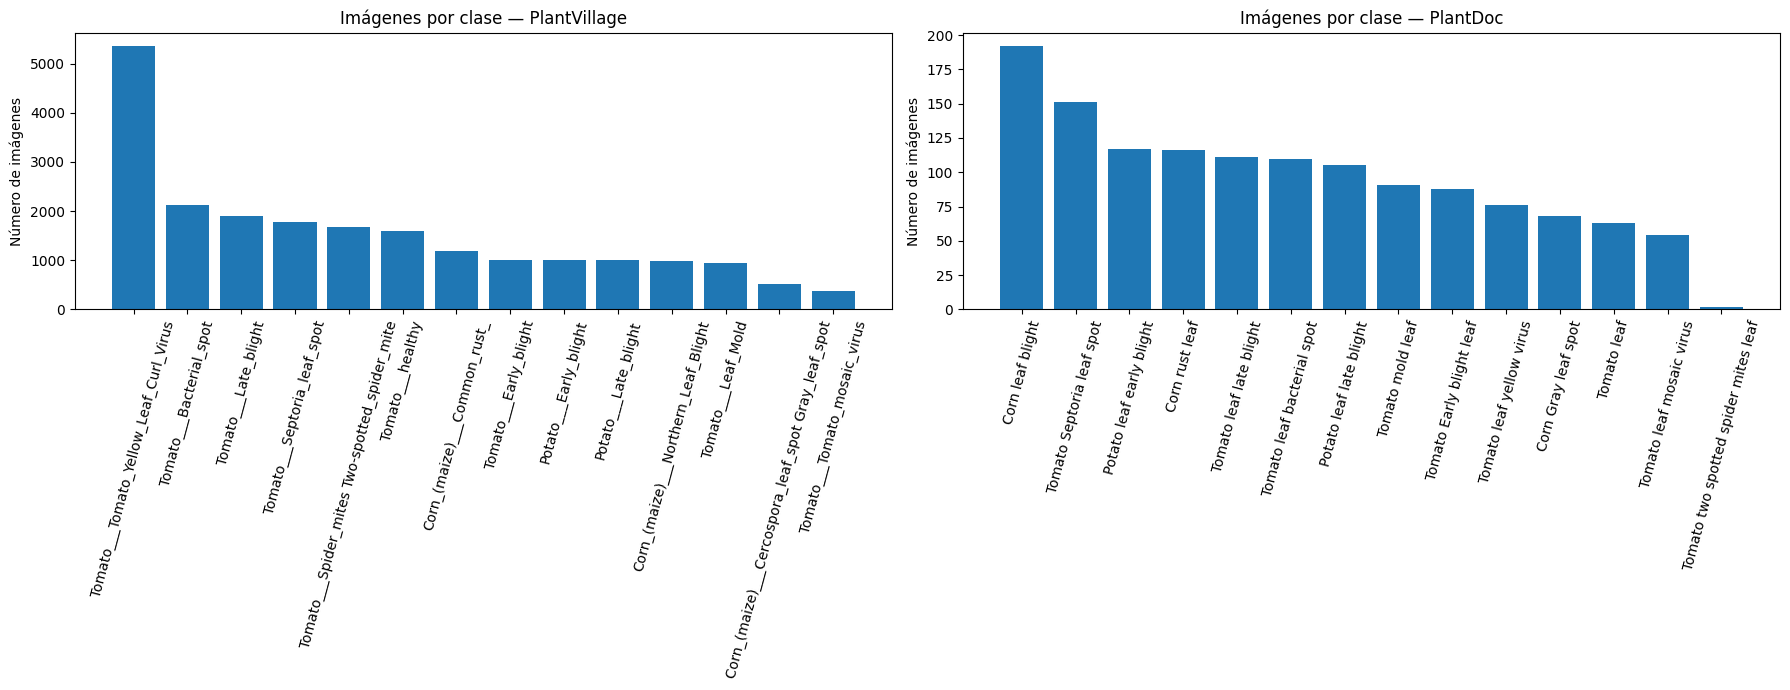

In [ ]:
# Gráfico de distribución de las 14 clases compatibles

import matplotlib.pyplot as plt

fig, axes = plt.subplots(
    1, 2,
    figsize=(18, 7)
)

for ax, fuente in zip(
    axes,
    ['PlantVillage', 'PlantDoc']
):

    data = resumen_compatible[
        resumen_compatible['fuente'] == fuente
    ].sort_values(
        'n_imagenes',
        ascending=False
    )

    ax.bar(
        data['clase'],
        data['n_imagenes']
    )

    ax.set_title(
        f'Imágenes por clase — {fuente}'
    )

    ax.set_ylabel(
        'Número de imágenes'
    )

    ax.tick_params(
        axis='x',
        rotation=75
    )

plt.tight_layout()

plt.savefig(
    '/content/grafico_14_clases_compatibles.png',
    dpi=200,
    bbox_inches='tight'
)

plt.show()

**Interpretación (completar después de ejecutar la celda anterior):**

> El Data-Set final de trabajo quedó compuesto por [n] imágenes de PlantVillage (entrenamiento/validación/prueba interna) y [n] imágenes de PlantDoc (evaluación externa), distribuidas en [N] clases compatibles. Esta tabla es la que se traslada directamente al informe como cierre de la Sección 3.1.4, sirviendo de base para el filtrado y la normalización descritos en la Sección 3.2.


## 3.2 — Normalización y/o Filtrado de Datos

3.2.1 — Filtrado de imágenes corruptas

In [ ]:
from PIL import Image

def find_corrupted(root_dir, exts=('.jpg', '.jpeg', '.png', '.JPG', '.JPEG', '.PNG')):
    corrupted = []
    for dirpath, _, filenames in os.walk(root_dir):
        for f in filenames:
            if f.endswith(exts):
                fpath = os.path.join(dirpath, f)
                try:
                    with Image.open(fpath) as img:
                        img.verify()
                except Exception:
                    corrupted.append(fpath)
    return corrupted

pv_final_dir = os.path.join(final_root, 'plantvillage')
corrupted_files = find_corrupted(pv_final_dir)
print(f'Imágenes corruptas encontradas: {len(corrupted_files)}')

for fpath in corrupted_files:
    os.remove(fpath)
print('Imágenes corruptas eliminadas.')

Imágenes corruptas encontradas: 0
Imágenes corruptas eliminadas.


3.2.2 — Filtrado de imágenes duplicadas

In [ ]:
!pip install -q imagehash
import imagehash

def find_duplicates(root_dir, exts=('.jpg', '.jpeg', '.png', '.JPG', '.JPEG', '.PNG')):
    seen = {}
    duplicates = []
    for dirpath, _, filenames in os.walk(root_dir):
        for f in filenames:
            if f.endswith(exts):
                fpath = os.path.join(dirpath, f)
                try:
                    h = str(imagehash.average_hash(Image.open(fpath)))
                except Exception:
                    continue
                if h in seen:
                    duplicates.append(fpath)
                else:
                    seen[h] = fpath
    return duplicates

duplicate_files = find_duplicates(pv_final_dir)
print(f'Imágenes duplicadas encontradas: {len(duplicate_files)}')

for fpath in duplicate_files:
    os.remove(fpath)
print('Imágenes duplicadas eliminadas.')

Imágenes duplicadas encontradas: 100
Imágenes duplicadas eliminadas.


3.2.3 — Redimensionamiento, normalización de píxeles y conversión de color

In [ ]:
IMG_SIZE = (224, 224)

def preprocess_image(fpath, size=IMG_SIZE):
    img = Image.open(fpath).convert('RGB')
    img = img.resize(size)
    arr = np.asarray(img).astype('float32') / 255.0
    return arr

sample_class_dir = glob.glob(os.path.join(pv_final_dir, '*', '*'))[0]
sample_files = [f for f in os.listdir(sample_class_dir) if f.lower().endswith(('.jpg', '.jpeg', '.png'))]
sample_path = os.path.join(sample_class_dir, sample_files[0])
sample_arr = preprocess_image(sample_path)

print('Ejemplo procesado:', sample_path)
print('Forma:', sample_arr.shape, '| rango:', sample_arr.min(), '-', sample_arr.max())

Ejemplo procesado: /content/dataset_final/plantvillage/maiz/Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot/c15dae11-38d1-47c3-99e0-c579ddeb3fb3___RS_GLSp 9269.JPG
Forma: (224, 224, 3) | rango: 0.0 - 1.0


3.2.4 — Codificación de etiquetas

In [ ]:
# 3.2 — Codificación de las 14 clases finales

def normalize_state(cls_name):

    name = cls_name.lower()

    name = re.sub(
        r'(tomato|potato|corn|maize)[_\s]*',
        '',
        name
    )

    name = re.sub(
        r'[^a-z]+',
        '_',
        name
    ).strip('_')

    return name


compat['estado'] = (
    compat['especie']
    + '_'
    + compat['clase_plantvillage'].apply(normalize_state)
)

clases_finales = sorted(
    compat['estado'].unique().tolist()
)

label_to_index = {
    label: idx
    for idx, label in enumerate(clases_finales)
}

print(
    f'Clases finales codificadas: {len(clases_finales)}'
)

for label, idx in label_to_index.items():
    print(f'{idx}: {label}')

# Verificación obligatoria
assert len(clases_finales) == 14, (
    f"ERROR: se esperaban 14 clases y "
    f"se obtuvieron {len(clases_finales)}"
)


Clases finales codificadas: 14
0: maiz_cercospora_leaf_spot_gray_leaf_spot
1: maiz_common_rust
2: maiz_northern_leaf_blight
3: papa_early_blight
4: papa_late_blight
5: tomate_bacterial_spot
6: tomate_early_blight
7: tomate_healthy
8: tomate_late_blight
9: tomate_leaf_mold
10: tomate_mosaic_virus
11: tomate_septoria_leaf_spot
12: tomate_spider_mites_two_spotted_spider_mite
13: tomate_yellow_leaf_curl_virus


3.2.5 — Aumento de datos (data augmentation)

In [ ]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

train_augmentor = ImageDataGenerator(
    rotation_range=20, horizontal_flip=True,
    brightness_range=(0.8, 1.2), rescale=1.0/255.0
)
eval_augmentor = ImageDataGenerator(rescale=1.0/255.0)
print('Generadores configurados: train_augmentor (con augmentation) y eval_augmentor (sin augmentation).')

Generadores configurados: train_augmentor (con augmentation) y eval_augmentor (sin augmentation).


## 3.3 — Planteamiento de la Organización del Data-Set

3.3.0 — Manifiesto de archivos y etiquetas

In [ ]:
# 3.2 — Construcción del manifiesto de PlantVillage

def build_manifest(root_dir, label_map):

    rows = []

    for esp_dir in glob.glob(
        os.path.join(root_dir, '*')
    ):

        especie = os.path.basename(
            esp_dir
        )

        for cls_dir in glob.glob(
            os.path.join(esp_dir, '*')
        ):

            cls_name = os.path.basename(
                cls_dir
            )

            estado = (
                especie
                + '_'
                + normalize_state(cls_name)
            )

            if estado not in label_map:
                continue

            for f in os.listdir(cls_dir):

                if f.lower().endswith(
                    ('.jpg', '.jpeg', '.png')
                ):

                    rows.append({
                        'filepath': os.path.join(
                            cls_dir,
                            f
                        ),
                        'especie': especie,
                        'clase': cls_name,
                        'estado': estado,
                        'label': label_map[estado]
                    })

    return pd.DataFrame(rows)


manifest = build_manifest(
    pv_final_dir,
    label_to_index
)

print(
    'Total de imágenes en el manifiesto:',
    len(manifest)
)

print(
    'Clases distintas:',
    manifest['label'].nunique()
)

print()
print('Distribución por clase:')

display(
    manifest[
        ['estado', 'label']
    ].groupby(
        ['label', 'estado']
    ).size()
    .reset_index(
        name='n_imagenes'
    )
    .sort_values('label')
)

assert manifest['label'].nunique() == 14
assert len(manifest) > 0

Total de imágenes en el manifiesto: 21346
Clases distintas: 14

Distribución por clase:


,label,estado,n_imagenes
0,0,maiz_cercospora_leaf_spot_gray_leaf_spot,513
1,1,maiz_common_rust,1192
2,2,maiz_northern_leaf_blight,985
3,3,papa_early_blight,1000
4,4,papa_late_blight,1000
5,5,tomate_bacterial_spot,2103
6,6,tomate_early_blight,999
7,7,tomate_healthy,1567
8,8,tomate_late_blight,1898
9,9,tomate_leaf_mold,947


evitar fuga de información

In [ ]:
# 3.3 — Identificación de grupos por hoja (leaf_id)

import json

leaf_map_path = os.path.join(
    pv_root,
    'leaf_grouping',
    'leaf-map.json'
)

print("Buscando:", leaf_map_path)

assert os.path.exists(
    leaf_map_path
), "No se encontró leaf-map.json"


with open(
    leaf_map_path,
    'r',
    encoding='utf-8'
) as f:

    leaf_map = json.load(f)


def get_leaf_id(filename):

    image_identifier = filename

    image_identifier = image_identifier.replace(
        '_final_masked',
        ''
    )

    if '___' in image_identifier:
        image_identifier = image_identifier.split(
            '___'
        )[-1]

    image_identifier = image_identifier.split(
        'copy'
    )[0]

    image_identifier = re.sub(
        r'\.(jpg|jpeg|png)$',
        '',
        image_identifier,
        flags=re.IGNORECASE
    )

    image_identifier = image_identifier.strip()

    lookup_key = image_identifier.lower().strip()

    if lookup_key not in leaf_map:
        return f'fallback_{lookup_key}'

    suggestions = leaf_map[lookup_key]

    if len(suggestions) == 1:
        return suggestions[0]

    for suggestion in suggestions:

        if suggestion in filename:
            return suggestion

    return f'fallback_{lookup_key}'


manifest['filename'] = manifest[
    'filepath'
].apply(
    lambda x: os.path.basename(x)
)

manifest['leaf_id'] = manifest[
    'filename'
].apply(get_leaf_id)

print(
    'Imágenes:', len(manifest)
)

print(
    'Leaf IDs únicos:',
    manifest['leaf_id'].nunique()
)

print()
display(
    manifest[
        [
            'filename',
            'leaf_id',
            'estado'
        ]
    ].head()
)

Buscando: /content/plantvillage/leaf_grouping/leaf-map.json
Imágenes: 21346
Leaf IDs únicos: 11417



,filename,leaf_id,estado
0,c15dae11-38d1-47c3-99e0-c579ddeb3fb3___RS_GLSp...,fallback_rs_glsp 9269,maiz_cercospora_leaf_spot_gray_leaf_spot
1,d007f0d4-30a4-4d9c-b193-09cef70b547b___RS_GLSp...,fallback_rs_glsp 4617,maiz_cercospora_leaf_spot_gray_leaf_spot
2,850945f0-128d-4e93-a2f9-d5e79bd0068c___RS_GLSp...,fallback_rs_glsp 4308,maiz_cercospora_leaf_spot_gray_leaf_spot
3,71deb36b-bebd-4f7e-8ed3-362b1bbf86b2___RS_GLSp...,fallback_rs_glsp 4446,maiz_cercospora_leaf_spot_gray_leaf_spot
4,94dbcd4e-5fc8-47d6-a944-dc0cc7c6ead5___RS_GLSp...,fallback_rs_glsp 4638,maiz_cercospora_leaf_spot_gray_leaf_spot


3.3.1 — Data-Set de entrenamiento (training)

In [ ]:
# 3.3.1 — División 80/20 respetando leaf_id

from sklearn.model_selection import StratifiedGroupKFold

X = manifest['filepath']
y = manifest['label']
groups = manifest['leaf_id']

# 5 folds estratificados y agrupados por hoja
sgkf = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

splits = list(
    sgkf.split(
        X,
        y,
        groups
    )
)

# Primer fold = TEST (20% aproximadamente)
train_idx, test_idx = splits[0]

train_df = manifest.iloc[
    train_idx
].copy().reset_index(drop=True)

test_df = manifest.iloc[
    test_idx
].copy().reset_index(drop=True)

print(
    '======================================'
)

print(
    'ENTRENAMIENTO:',
    len(train_df),
    f'({len(train_df)/len(manifest):.2%})'
)

print(
    'PRUEBA:',
    len(test_df),
    f'({len(test_df)/len(manifest):.2%})'
)

print(
    '======================================'
)

# Comprobar que no existe una misma hoja
# en entrenamiento y prueba

train_groups = set(
    train_df['leaf_id']
)

test_groups = set(
    test_df['leaf_id']
)

intersection = train_groups.intersection(
    test_groups
)

print(
    'Leaf IDs compartidos entre train y test:',
    len(intersection)
)

assert len(intersection) == 0

ENTRENAMIENTO: 17049 (79.87%)
PRUEBA: 4297 (20.13%)
Leaf IDs compartidos entre train y test: 0


3.3.2 — Data-Set de pruebas (test)

In [ ]:
# 3.3.2 — Data-Set de pruebas (test)
from sklearn.model_selection import StratifiedKFold

print('Prueba (test):', len(test_df), 'imágenes', f'({len(test_df)/len(manifest):.1%})')
test_df['label'].value_counts()

# 3.3.3 — Validación mediante Cross-Validation (k=5) sobre el 80% de entrenamiento
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
fold_sizes = [len(idx) for _, idx in skf.split(train_df['filepath'], train_df['label'])]
print('Tamaños de cada fold (k=5):', fold_sizes)

Prueba (test): 4297 imágenes (20.1%)
Tamaños de cada fold (k=5): [3410, 3410, 3410, 3410, 3409]


3.3.3 — Data-Set de validación ("Cross-Validation")

In [ ]:
# 3.3.2 — Validación cruzada estratificada por grupos
# k = 5 sobre el conjunto de entrenamiento

X_train = train_df['filepath']
y_train = train_df['label']
groups_train = train_df['leaf_id']

cv = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

fold_info = []

for fold, (tr_idx, val_idx) in enumerate(
    cv.split(
        X_train,
        y_train,
        groups_train
    ),
    start=1
):

    fold_train = train_df.iloc[
        tr_idx
    ]

    fold_val = train_df.iloc[
        val_idx
    ]

    train_groups = set(
        fold_train['leaf_id']
    )

    val_groups = set(
        fold_val['leaf_id']
    )

    shared = train_groups.intersection(
        val_groups
    )

    print(
        f'Fold {fold}:'
    )

    print(
        f'  Entrenamiento: {len(fold_train)}'
    )

    print(
        f'  Validación:    {len(fold_val)}'
    )

    print(
        f'  Leaf IDs compartidos: {len(shared)}'
    )

    print()

    assert len(shared) == 0

    fold_info.append({
        'fold': fold,
        'train': len(fold_train),
        'validation': len(fold_val)
    })

fold_info_df = pd.DataFrame(
    fold_info
)

display(fold_info_df)

Fold 1:
  Entrenamiento: 13649
  Validación:    3400
  Leaf IDs compartidos: 0

Fold 2:
  Entrenamiento: 13625
  Validación:    3424
  Leaf IDs compartidos: 0

Fold 3:
  Entrenamiento: 13640
  Validación:    3409
  Leaf IDs compartidos: 0

Fold 4:
  Entrenamiento: 13649
  Validación:    3400
  Leaf IDs compartidos: 0

Fold 5:
  Entrenamiento: 13633
  Validación:    3416
  Leaf IDs compartidos: 0



,fold,train,validation
0,1,13649,3400
1,2,13625,3424
2,3,13640,3409
3,4,13649,3400
4,5,13633,3416


Cierre — guardado de manifiestos

In [ ]:
# 3.3.3 — Guardado de manifiestos

train_df.to_csv(
    '/content/manifest_train.csv',
    index=False
)

test_df.to_csv(
    '/content/manifest_test.csv',
    index=False
)

fold_info_df.to_csv(
    '/content/cross_validation_folds.csv',
    index=False
)

print('======================================')
print('RESUMEN DE PARTICIONES')
print('======================================')

print(
    f'Total dataset : {len(manifest)}'
)

print(
    f'Train         : {len(train_df)} '
    f'({len(train_df)/len(manifest):.2%})'
)

print(
    f'Test          : {len(test_df)} '
    f'({len(test_df)/len(manifest):.2%})'
)

print()
print(
    'Validación: 5-fold Cross-Validation '
    'sobre el conjunto de entrenamiento.'
)

print()
print(
    'No se utiliza un val_df independiente.'
)

RESUMEN DE PARTICIONES
Total dataset : 21346
Train         : 17049 (79.87%)
Test          : 4297 (20.13%)

Validación: 5-fold Cross-Validation sobre el conjunto de entrenamiento.

No se utiliza un val_df independiente.
